In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
# importamos as bibliotecas de tratamento de dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
# importamos as bibliotecas de IA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [33]:
# importamos a biblioteca para gestão do tempo
import time

In [34]:
input_file = '/content/drive/MyDrive/dados_baterias_litio.csv'

df = pd.read_csv(input_file)

display(df.head())

,Resistencia_mOhms,Temp_Pico_C,Defeito
0,9.32,45.28,0
1,18.17,69.40,0
2,14.17,6.85,1
3,2.94,56.86,0
4,8.11,80.87,1


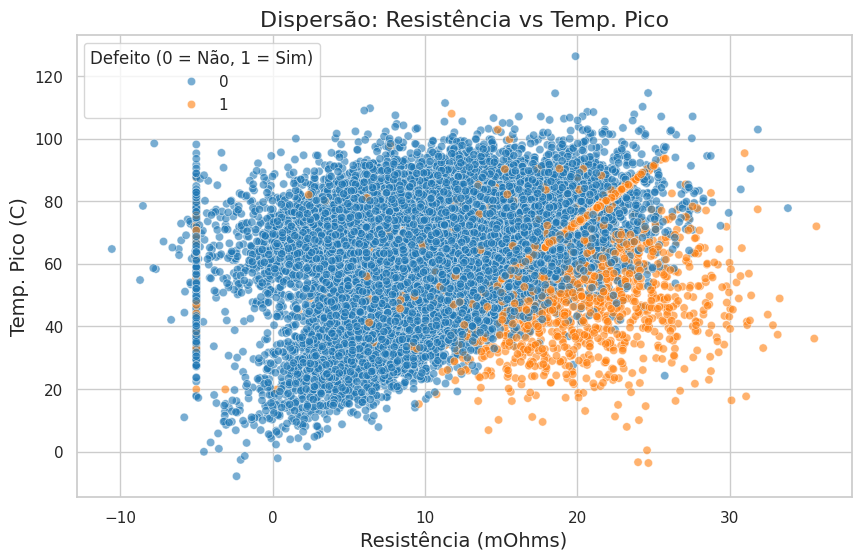

In [35]:
# imprimimos os dados para tentar enxergar alguma anomalia
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='Resistencia_mOhms',
    y='Temp_Pico_C',
    hue='Defeito',
    palette='tab10',
    alpha=0.6
)

plt.title('Dispersão: Resistência vs Temp. Pico', fontsize=16)
plt.xlabel('Resistência (mOhms)', fontsize=14)
plt.ylabel('Temp. Pico (C)', fontsize=14)
plt.legend(title='Defeito (0 = Não, 1 = Sim)')
plt.show()

In [36]:
# no gráfico vemos que existem resistências negativas, o que é impossível, então removemos
df_fixed = df[df['Resistencia_mOhms'] > 0]

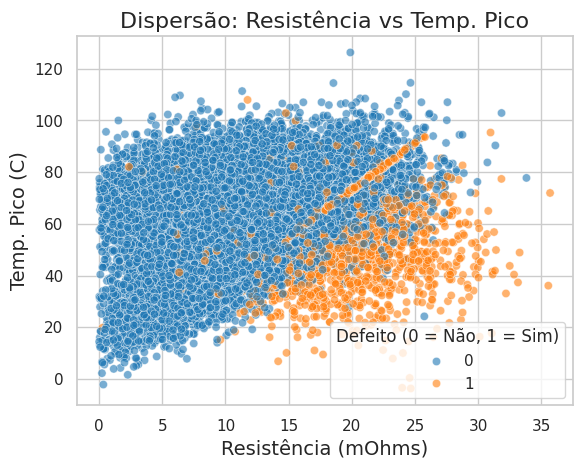

In [37]:
# imprimimos novamente para detectar a correção
sns.scatterplot(
    data=df_fixed,
    x='Resistencia_mOhms',
    y='Temp_Pico_C',
    hue='Defeito',
    palette='tab10',
    alpha=0.6
)

plt.title('Dispersão: Resistência vs Temp. Pico', fontsize=16)
plt.xlabel('Resistência (mOhms)', fontsize=14)
plt.ylabel('Temp. Pico (C)', fontsize=14)
plt.legend(title='Defeito (0 = Não, 1 = Sim)')
plt.show()

In [38]:
# separamos os dados de entrada e saída
X = df_fixed[['Resistencia_mOhms', 'Temp_Pico_C']]
y = df_fixed['Defeito']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)


In [39]:
# o K-NN precisa dos dados na mesma escala
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
# Teste usando o K-NN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

start_knn = time.time()
pred_knn = knn.predict(X_test_scaled)
timing_knn = time.time() - start_knn

acc_knn = accuracy_score(y_test, pred_knn)
print("Acurácia do K-NN:", acc_knn)
print("Tempo de execução do K-NN:", timing_knn)


Acurácia do K-NN: 0.939413895291406
Tempo de execução do K-NN: 0.016487836837768555


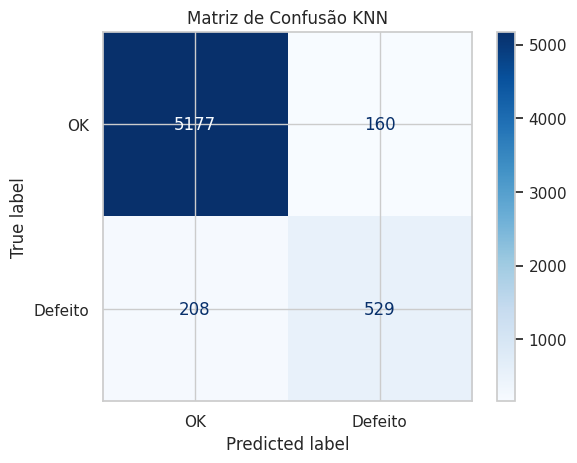

In [48]:
cm_knn = confusion_matrix(y_test, pred_knn)
ConfusionMatrixDisplay.from_predictions(y_test, pred_knn, display_labels=['OK', 'Defeito'], cmap='Blues')
plt.title("Matriz de Confusão KNN")
plt.show()

In [42]:
bayes = GaussianNB()
bayes.fit(X_train_scaled, y_train)

start_bayes = time.time()
pred_bayes = bayes.predict(X_test_scaled)
timing_bayes = time.time() - start_bayes

acc_bayes = accuracy_score(y_test, pred_bayes)
print("Acurácia do Bayesiano:", acc_bayes)
print("Tempo de execução do Bayesiano:", timing_bayes)

Acurácia do Bayesiano: 0.8903523213697728
Tempo de execução do Bayesiano: 0.002434253692626953


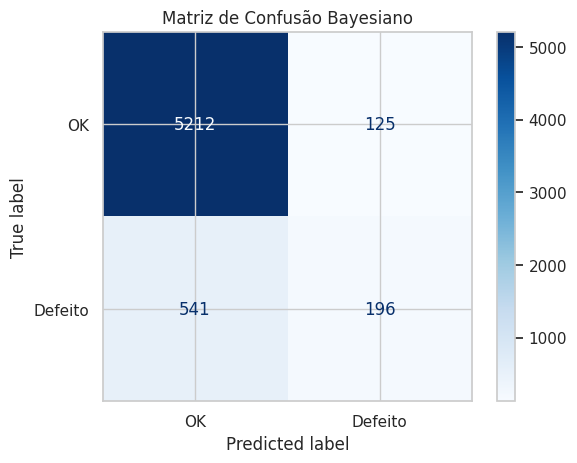

In [49]:
cm_knn = confusion_matrix(y_test, pred_bayes)
ConfusionMatrixDisplay.from_predictions(y_test, pred_bayes, display_labels=['OK', 'Defeito'], cmap='Blues')
plt.title("Matriz de Confusão Bayesiano")
plt.show()